# Approach

Given the fair price range for each product, the quantity bought, and the total paid, we can determine which pilots bought each souvenir at least once at a fair price.

In [1]:
import pandas as pd

purchases = pd.read_csv("data/purchases.csv")
guide = pd.read_csv("data/office_price_guide.csv")

We use the product as the key and store its minimum and maximum fair prices per unit as a tuple.

In [2]:
products = {}
product_prices = guide.loc[:, ['Product', 'Fair_min_eur', 'Fair_max_eur']]

def parse_prices(price):
    products[price.Product] = (price.Fair_min_eur, price.Fair_max_eur)
    return price

product_prices.apply(parse_prices, axis='columns') 
print(products)

{'Jamon': (35.0, 80.0), 'Churros': (3.0, 7.0), 'Turron': (6.0, 15.0), 'Paella': (20.0, 45.0), 'Saffron': (5.0, 12.0), 'Barquillos': (4.0, 10.0)}


We divide the total paid by the quantity and add a `fair_price` column. A receipt qualifies when its unit price falls within the product's fair range.

In [3]:
def validate_price(purchase):
    (minP, maxP) = products[purchase.Product]
    price = purchase.Total_paid_eur / purchase.Quantity
    purchase["fair_price"] = price <= maxP and price >= minP

    return purchase

purchases = purchases.apply(validate_price, axis='columns')

We create a pivot table from `purchases` using `Product` as the index and `Pilot_no` as the columns. The `any` aggregation makes a cell `True` when at least one receipt for that pair has `fair_price` set to `True`.

Before plotting, we reindex the board with products in `List_no` order and pilots numbered 1 through 21. Missing pairs are `False`, giving us a 6 × 21 DataFrame.

In [4]:
ordered_products = guide.sort_values(by="List_no").Product

pilot_board = purchases.pivot_table(
    index="Product",
    columns="Pilot_no",
    values="fair_price",
    aggfunc="any",
    fill_value=False,
)

pilot_board = pilot_board.reindex(
    index=ordered_products,
    columns=range(1, 22),
    fill_value=False,
)

pilot_board

Pilot_no,1,2,3,4,5,6,7,8,9,10,...,12,13,14,15,16,17,18,19,20,21
Product,,,,,,,,,,,,,,,,,,,,,
Jamon,False,False,False,False,True,True,False,False,False,False,...,False,True,True,True,False,False,False,True,True,True
Churros,False,False,False,False,True,False,True,False,False,False,...,False,True,False,False,False,True,False,True,False,True
Turron,True,True,True,False,True,False,True,False,True,False,...,False,True,False,False,False,False,False,True,False,True
Paella,True,False,False,False,True,True,False,False,True,False,...,False,True,False,False,False,True,False,True,False,True
Saffron,True,False,False,False,True,False,True,False,True,False,...,False,True,False,False,False,True,False,True,False,True
Barquillos,True,True,True,False,True,False,True,False,True,True,...,False,True,True,True,False,True,False,True,True,True


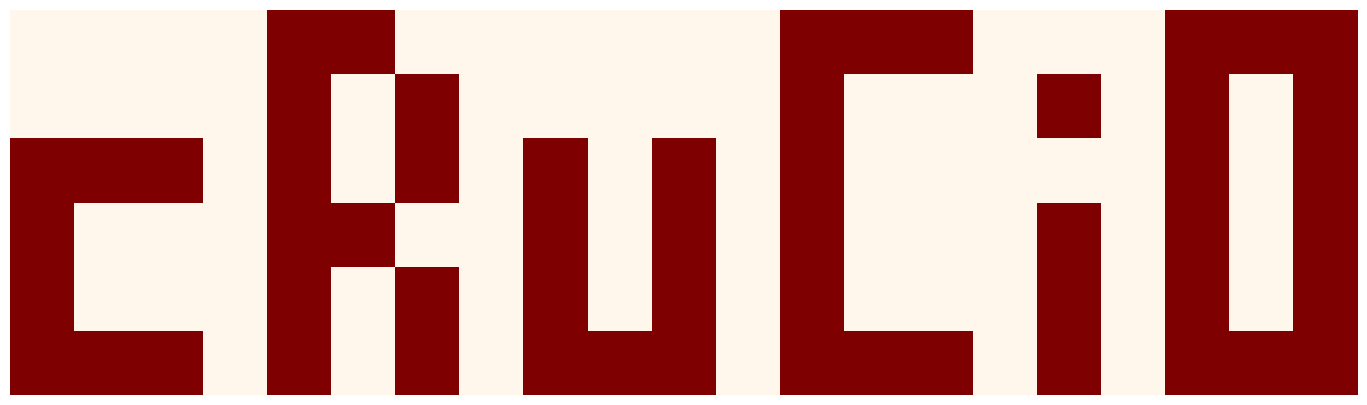

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(24, 5))
plt.imshow(pilot_board, cmap="OrRd", interpolation="nearest")
plt.axis("off")
plt.savefig("figures/crucio.png", dpi=150, bbox_inches="tight")
plt.show()

# Result

The newly arranged data reveals **CRUCIO** as the final answer.

Flag: `SIGMOID_CRUCIO`